In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv(r"C:\Users\Zohair\Downloads\Automobile_Dealership_Sales_RAW_v2.csv", encoding= 'unicode escape', low_memory= False)

In [4]:
df.shape

(22351, 32)

In [5]:
df.isna().sum()

Sale_ID                   40
Sale_Date                 41
Delivery_Date             41
Registration_Number     2309
Customer_Name             41
Customer_Age            4369
Customer_Phone          3280
Customer_Email          2902
Car_Brand                 41
Car_Model                 41
Fuel_Type                 41
Transmission              41
Color                     41
Manufacturing_Year      2908
KM_Driven               3761
Odometer_Unit             41
Price                     41
GST_Amount              2291
Discount                3193
Total_Payable           3400
Payment_Mode              41
Financing_Bank          7007
Insurance_Provider      5644
Salesperson               41
City                      41
State                     41
Warranty_Years          6493
Test_Drive_Done         2068
Exchange_Vehicle        3218
Referral_Source         2849
Quantity                  40
Unnamed: 29            22351
dtype: int64

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22351 entries, 0 to 22350
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Sale_ID              22311 non-null  object 
 1   Sale_Date            22310 non-null  object 
 2   Delivery_Date        22310 non-null  object 
 3   Registration_Number  20042 non-null  object 
 4   Customer_Name        22310 non-null  object 
 5   Customer_Age         17982 non-null  object 
 6   Customer_Phone       19071 non-null  object 
 7   Customer_Email       19449 non-null  object 
 8   Car_Brand            22310 non-null  object 
 9   Car_Model            22310 non-null  object 
 10  Fuel_Type            22310 non-null  object 
 11  Transmission         22310 non-null  object 
 12  Color                22310 non-null  object 
 13  Manufacturing_Year   19443 non-null  object 
 14  KM_Driven            18590 non-null  object 
 15  Odometer_Unit        22310 non-null 

## --> Start Data Cleaning

In [7]:
junk_cols = [c for c in df.columns if 'Unnamed:' in str(c) or isinstance(c, tuple) or 'Test_Drive_Done,' in str(c)]
df.drop(columns= junk_cols, inplace= True, errors= 'ignore')

df.dropna(how= 'all', inplace= True)

In [8]:
if len(df) >0:
    header_mask = df.apply(lambda a: sum(str(a[c]) == str(c) for c in df.columns)/ len(df.columns) >=0.8, axis=1)
    df = df[~header_mask]

In [9]:
def fix_encoding(val):
    if pd.isna(val) or str(val).strip().lower() in ['nan', 'none', 'na', '']:
        return np.nan
    val_str = str(val).strip()
    try:
        return val_str.encode('latin1').decode('utf-8')
    except (UnicodeEncodeError,UnicodeDecodeError):
        return val_str
df['City'] = df['City'].apply(fix_encoding)

city_map = {
    'BOMBAY':'Mumbai', 'MUMBAI':'Mumbai',
    'CALCUTTA':'Kolkata', 'KOLKATA':'Kolkata',
    'MADRAS':'Chennai', 'CHENNAI':'Chennai'
}

df['City'] = df['City'].astype(str).str.strip().str.upper()
df['City'] = df['City'].replace(city_map).str.title()
df['City'] = df['City'].replace({'Nan': np.nan, 'None':np.nan, '':np.nan})

In [10]:
df['Test_Drive_Done'] = df['Test_Drive_Done'].astype(str).str.strip().str.upper().map(
    {'Y':'Yes', 'YES':'Yes', '1':'Yes', 'N':'No', 'NO':'No', '0':'No'})

df['Exchange_Vehicle'] = df['Exchange_Vehicle'].astype(str).str.strip().str.upper().map(
    {'YES':'True', 'TRUE':'True', '1':'True', 'NO':'False', 'FALSE':'False', '0':'False'})

df['Fuel_Type'] = df['Fuel_Type'].astype(str).str.strip().replace({'EV':'Electric'})

df['Transmission'] = df['Transmission'].astype(str).str.strip().replace({'AMT':'Automated Manual Transmission', 'AT':'Automatic', 'MT':'Manual'})

df['Color'] = df['Color'].astype(str).str.strip().replace({'Gray':'GREY'})

df['Odometer_Unit'] = df['Odometer_Unit'].astype(str).str.strip().replace({'mi':'Miles'})

state_map = {'PB':'Punjab', 'RJ':'Rajasthan', 'UP':'Uttar Pradesh', 'MP':'Madhya Pradesh'}
df['State'] = df['State'].astype(str).str.strip().str.upper().replace(state_map).str.title()

bank_map = {'AXIS':'Axis Bank', 'HDFC':'HDFC Bank', 'HDFC BANK':'HDFC Bank', 'hdfc bank':'HDFC Bank',
           'ICICI':'ICICI Bank', 'State Bank of India':'SBI', 'STATE BANK OF INDIA':'SBI'}
df['Financing_Bank'] = df['Financing_Bank'].astype(str).str.strip().replace(bank_map)
df['Financing_Bank'] = df['Financing_Bank'].replace(['nan', 'NaN', 'NAN'],np.nan)

Text_cols = ['Customer_Name', 'Car_Brand', 'Car_Model', 'Fuel_Type', 'Transmission', 
             'Color', 'Odometer_Unit', 'Payment_Mode', 'Insurance_Provider', 
             'Salesperson', 'Referral_Source']
for a in Text_cols:
    df[a] = df[a].astype(str).str.strip()
    df[a] = df[a].replace({'nan':np.nan, 'NAN':np.nan, 'None':np.nan, 'NA':np.nan, '':np.nan})
    df[a] = df[a].str.title()

In [11]:
df['Customer_Age'] = pd.to_numeric(df['Customer_Age'], errors='coerce')
df.loc[(df['Customer_Age'] <18) | (df['Customer_Age'] >100), 'Customer_Age'] = np.nan

df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df.loc[(df['Quantity'] <=0) | (df['Quantity'] >10), 'Quantity'] =  np.nan


Num_cols = ['GST_Amount', 'Discount', 'Total_Payable', 'KM_Driven', 'Warranty_Years']
for a in Num_cols:
    df[a] = df[a].astype(str).str.replace(r'[^\d.]', '', regex =True)
    df[a] = pd.to_numeric(df[a], errors='coerce')
    df.loc[df[a] <=0, a] = np.nan

df['Price'] = df['Price'].astype(str).str.replace(r'[^\d.]', '', regex=True)
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')
df.loc[df['Price'] <50000, 'Price'] = np.nan

In [12]:
df['Sale_Date'] = pd.to_datetime(df['Sale_Date'], format= 'mixed', errors='coerce')
df['Delivery_Date'] = pd.to_datetime(df['Delivery_Date'], format='mixed', errors='coerce')

df.loc[df['Delivery_Date'] <df['Sale_Date'], 'Delivery_Date'] = pd.NaT

df['Years_Sales'] = df['Sale_Date'].dt.year
df['Months_Sales'] = df['Sale_Date'].dt.month_name()
df['Days_Sales'] = df['Sale_Date'].dt.day_name()

In [13]:
df['Manufacturing_Year'] = pd.to_numeric(df['Manufacturing_Year'], errors='coerce')
df['Manufacturing_Year'] = df.groupby('Car_Model')['Manufacturing_Year'].transform(lambda a: a.fillna(a.median()))

if 'Years_Sales' in df.columns:
    avg_age = (df['Years_Sales'] - df['Manufacturing_Year']).median()
    df['Manufacturing_Year'] = df['Manufacturing_Year'].fillna(df['Years_Sales'] - avg_age)
df['Manufacturing_Year'] = df['Manufacturing_Year'].fillna(df['Manufacturing_Year'].median()).astype(int)

In [14]:
df['Price'] = df.groupby('Car_Model')['Price'].transform(lambda a: a.fillna(a.median()))
df['Price'] = df['Price'].fillna(df['Price'].median())

In [15]:
df['Customer_Age'] = df.groupby('Car_Model')['Customer_Age'].transform(lambda a: a.fillna(a.median()))
df['Customer_Age'] = df['Customer_Age'].fillna(df['Customer_Age'].median()).astype(int)

df['Quantity'] = df['Quantity'].fillna(1).astype(int)

for a in ['GST_Amount', 'Discount', 'Total_Payable', 'KM_Driven', 'Warranty_Years']:
    df[a] = df[a].fillna(df[a].median())

In [16]:
df['Sale_Date'] = df['Sale_Date'].ffill()
avg_delay = (df['Delivery_Date'] - df['Sale_Date']).dt.days.median()
df['Delivery_Date'] = df['Delivery_Date'].fillna(df['Sale_Date'] + pd.Timedelta(days = avg_delay))

In [17]:
all_cate_null = Text_cols + ['City', 'State', 'Financing_Bank', 'Test_Drive_Done', 'Exchange_Vehicle']
for a in all_cate_null:
    if df[a].isna().sum() >=0:
        df[a] = df[a].fillna(df[a].mode()[0])

In [18]:
df['Customer_Email'] = df['Customer_Email'].fillna('Not Provided')
df['Customer_Phone'] = df['Customer_Phone'].str.strip().replace({'':np.nan}).fillna('Not Provided')
df['Registration_Number'] = df['Registration_Number'].fillna('Unknown')

In [19]:
df.drop_duplicates(inplace= True)

In [20]:
df.isna().sum()

Sale_ID                0
Sale_Date              0
Delivery_Date          0
Registration_Number    0
Customer_Name          0
Customer_Age           0
Customer_Phone         0
Customer_Email         0
Car_Brand              0
Car_Model              0
Fuel_Type              0
Transmission           0
Color                  0
Manufacturing_Year     0
KM_Driven              0
Odometer_Unit          0
Price                  0
GST_Amount             0
Discount               0
Total_Payable          0
Payment_Mode           0
Financing_Bank         0
Insurance_Provider     0
Salesperson            0
City                   0
State                  0
Warranty_Years         0
Test_Drive_Done        0
Exchange_Vehicle       0
Referral_Source        0
Quantity               0
Years_Sales            1
Months_Sales           1
Days_Sales             1
dtype: int64

In [21]:
bins = [17, 40, 60, 100]
labels = ['18to40', '41to60', '60+']

df['Age_Group'] = pd.cut(df['Customer_Age'], bins=bins, labels=labels, right=True)

In [22]:
df.head(50)

,Sale_ID,Sale_Date,Delivery_Date,Registration_Number,Customer_Name,Customer_Age,Customer_Phone,Customer_Email,Car_Brand,Car_Model,...,State,Warranty_Years,Test_Drive_Done,Exchange_Vehicle,Referral_Source,Quantity,Years_Sales,Months_Sales,Days_Sales,Age_Group
0,SL29437,2022-06-23,2022-07-08,DE-97-CD-4517,Aisha Reddy,46,91659 88633,aisha.reddy78@gmail.com,Tata,Altroz,...,Delhi,2.0,No,False,Walk-In,1,2022.0,June,Thursday,41to60
1,SL13664,2024-10-12,2024-10-30,MA-34-XY-4864,Rahul Khan,53,67740 45915,rahul.khan59@gmail.com,Honda,Elevate,...,Maharashtra,2.0,No,False,Online,1,2024.0,October,Saturday,41to60
2,SL26787,2023-04-01,2023-05-01,RA-80-AB-1991,Karan Reddy,52,8800251710 ext. 12,karan.reddy24@gmail.com,Hyundai,Venue,...,Rajasthan,2.0,No,False,Referral,1,2023.0,April,Saturday,41to60
3,SL23454,2022-01-19,2022-02-05,KA-74-AB-3578,Sunita Khan,43,6420567449,sunita.khan79@gmail.com,Toyota,Innova,...,Karnataka,3.0,Yes,True,Social Media,2,2022.0,January,Wednesday,41to60
4,SL11793,2022-10-24,2022-11-05,PU-25-XY-8814,Aisha Khan,40,Not Provided,aisha.khan99@gmail.com,Tata,Harrier,...,Punjab,2.0,No,True,Walk-In,2,2022.0,October,Monday,18to40
5,SL22037,2022-06-19,2022-06-24,MA-53-CD-8945,Aisha Reddy,43,9596521518,aisha.reddy15@gmail.com,Hyundai,Creta,...,Maharashtra,1.0,Yes,True,Walk-In,1,2022.0,June,Sunday,41to60
6,SL31127,2024-02-06,2024-02-07,DE-30-AB-9938,Priya Khan,62,7372733464,priya.khan66@gmail.com,Honda,Amaze,...,Delhi,2.0,No,True,Walk-In,1,2024.0,February,Tuesday,60+
7,SL15897,2025-01-24,2025-02-03,MA-05-AB-9863,Priya Patel,23,89873 44888,Not Provided,Tata,Harrier,...,Maharashtra,1.0,No,False,Social Media,2,2025.0,January,Friday,18to40
8,SL29106,2022-12-09,2022-12-14,MA-82-AB-8649,Karan Patel,42,93220 24341,karan.patel73@gmail.com,Tata,Nexon,...,Maharashtra,3.0,No,True,Social Media,2,2022.0,December,Friday,41to60
9,SL16424,2023-02-14,2023-02-18,MA-04-AB-6714,Sunita Sharma,38,7104393895,sunita.sharma92@gmail.com,Tata,Punch,...,Maharashtra,1.0,No,True,Online,1,2023.0,February,Tuesday,18to40


In [23]:
df.tail(50)

,Sale_ID,Sale_Date,Delivery_Date,Registration_Number,Customer_Name,Customer_Age,Customer_Phone,Customer_Email,Car_Brand,Car_Model,...,State,Warranty_Years,Test_Drive_Done,Exchange_Vehicle,Referral_Source,Quantity,Years_Sales,Months_Sales,Days_Sales,Age_Group
22300,SL10931,2022-11-27,2022-12-09,GU-37-XY-9126,Rahul Verma,41,9562339652,rahul.verma42@gmail.com,Kia,Carens,...,Gujarat,2.0,No,False,Referral,1,2022.0,November,Sunday,41to60
22301,SL28788,2023-03-19,2023-03-22,MA-83-XY-3514,Sunita Verma,42,9489479763,"sunita992@gmail,com",Mahindra,Xuv700,...,Maharashtra,2.0,Yes,True,Walk-In,1,2023.0,March,Sunday,41to60
22302,SL19877,2024-04-14,2024-04-22,MA-95-AB-3057,Sunita Khan,61,-8274161396,sunita.khan74@gmail.com,Mahindra,Bolero,...,Maharashtra,2.0,No,False,Walk-In,1,2024.0,April,Sunday,60+
22303,SL11248,2022-07-28,2022-07-29,WE-46-XY-1474,Aisha Patel,28,Not Provided,"aisha237@gmail,com",Tata,Harrier,...,West Bengal,3.0,Yes,True,Walk-In,2,2022.0,July,Thursday,18to40
22304,SL14855,2022-07-12,2022-07-27,DE-02-AB-8957,Priya Patel,31,Not Provided,priya414@gmial.com,Maruti Suzuki,Dzire,...,Delhi,3.0,Yes,False,Walk-In,1,2022.0,July,Tuesday,18to40
22305,SL26476,2024-11-08,2024-11-23,KA-77-XY-8918,Aisha Khan,56,-6573845911,aisha.khan16@gmail.com,Honda,Amaze,...,Karnataka,2.0,No,True,Social Media,1,2024.0,November,Friday,41to60
22306,SL31895,2023-08-10,2023-08-30,MA-46-AB-9887,Karan Patel,42,99171 28470,karan.patel75@gmail.com,Hyundai,Grand I10,...,Maharashtra,3.0,No,True,Advertisement,1,2023.0,August,Thursday,41to60
22307,SL15437,2025-03-22,2025-03-31,WE-17-CD-7197,Priya Patel,42,73021 20018,priya.patel45@gmail.com,Mahindra,Xuv700,...,West Bengal,1.0,Yes,False,Referral,1,2025.0,March,Saturday,41to60
22309,SL29235,2024-11-18,2024-11-30,MA-98-CD-5382,Aisha Reddy,40,8547559660,aisha234@gmial.com,Hyundai,I20,...,Maharashtra,2.0,Yes,False,Online,2,2024.0,November,Monday,18to40
22310,SL20985,2023-06-25,2023-07-07,GU-91-CD-2651,Priya Khan,27,6010630136,priya.khan38@gmail.com,Tata,Altroz,...,Gujarat,3.0,No,True,Walk-In,1,2023.0,June,Sunday,18to40


## --> Let's Build Visuals

In [24]:
df.loc[(df['Manufacturing_Year'] < 1900) |
       (df['Manufacturing_Year'] > df['Years_Sales']), 'Manufacturing_Year'] = np.nan

df.loc[(df['KM_Driven'] < 0) | (df['KM_Driven'] > 500000), 'KM_Driven'] = np.nan

df.loc[(df['Discount'] < 0) | (df['Discount'] > df['Price']), 'Discount'] = np.nan

df.loc[df['GST_Amount'] < 0, 'GST_Amount'] = np.nan
df.loc[df['Total_Payable'] < 0, 'Total_Payable'] = np.nan
df.loc[(df['Quantity'] <= 0) | (df['Quantity'] > 10), 'Quantity'] = np.nan
df.loc[(df['Warranty_Years'] < 0) | (df['Warranty_Years'] > 20), 'Warranty_Years'] = np.nan


cols = ['Manufacturing_Year','KM_Driven','Discount',
        'GST_Amount','Total_Payable','Warranty_Years']

for col in cols:
    df[col] = df[col].fillna(df[col].median())

df['Quantity'] = df['Quantity'].fillna(1).astype(int)


In [25]:
df[['Customer_Age',
    'Manufacturing_Year',
    'KM_Driven',
    'Price',
    'GST_Amount',
    'Discount',
    'Total_Payable',
    'Warranty_Years',
    'Quantity']].describe()

,Customer_Age,Manufacturing_Year,KM_Driven,Price,GST_Amount,Discount,Total_Payable,Warranty_Years,Quantity
count,22001.000000,22001.000000,22001.000000,2.200100e+04,22001.000000,2.200100e+04,2.200100e+04,22001.000000,22001.000000
mean,42.970365,2021.798782,4573.921776,1.316596e+06,238067.348904,2.066149e+04,1.527707e+06,2.006863,1.140766
std,8.291969,0.932402,10818.333755,3.912021e+05,86405.338169,3.881955e+04,5.623524e+05,0.755223,0.347788
min,21.000000,2020.000000,118.000000,4.501740e+05,81007.380000,5.000000e+03,2.983940e+03,1.000000,1.000000
25%,41.000000,2021.000000,500.000000,1.171649e+06,168107.400000,1.000000e+04,1.103045e+06,1.000000,1.000000
50%,43.000000,2022.000000,500.000000,1.307526e+06,237859.380000,1.500000e+04,1.524001e+06,2.000000,1.000000
75%,45.000000,2022.000000,500.000000,1.451533e+06,308741.400000,2.500000e+04,1.961707e+06,3.000000,1.000000
max,65.000000,2024.000000,49989.000000,2.199792e+06,395976.420000,1.336502e+06,2.595845e+06,3.000000,2.000000


C:\Users\Zohair\AppData\Local\Temp\ipykernel_10076\4184022340.py:12: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\ProgramData\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


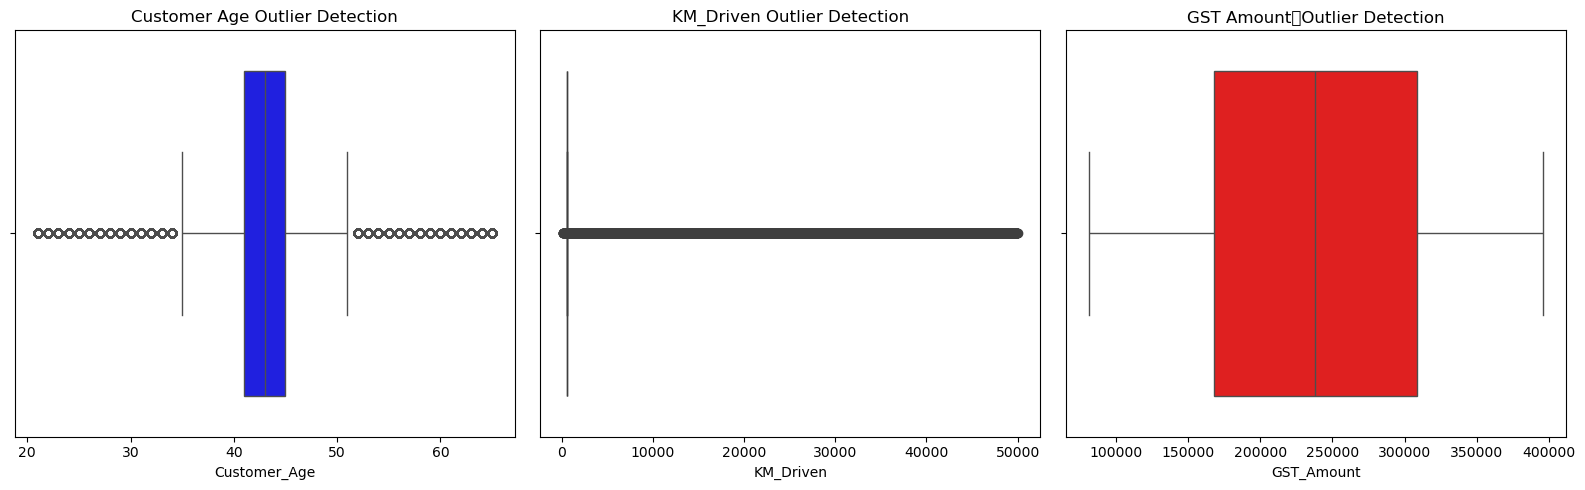

In [26]:
fig, ax= plt.subplots(1,3, figsize= (16,5))

sns.boxplot(x= df['Customer_Age'], ax= ax[0], color= 'blue')
ax[0].set_title('Customer Age Outlier Detection')

sns.boxplot(x= df['KM_Driven'], ax= ax[1])
ax[1].set_title('KM_Driven Outlier Detection')

sns.boxplot(x= df['GST_Amount'], ax= ax[2], color= 'red')
ax[2].set_title('GST Amount	Outlier Detection')

plt.tight_layout()
plt.show()

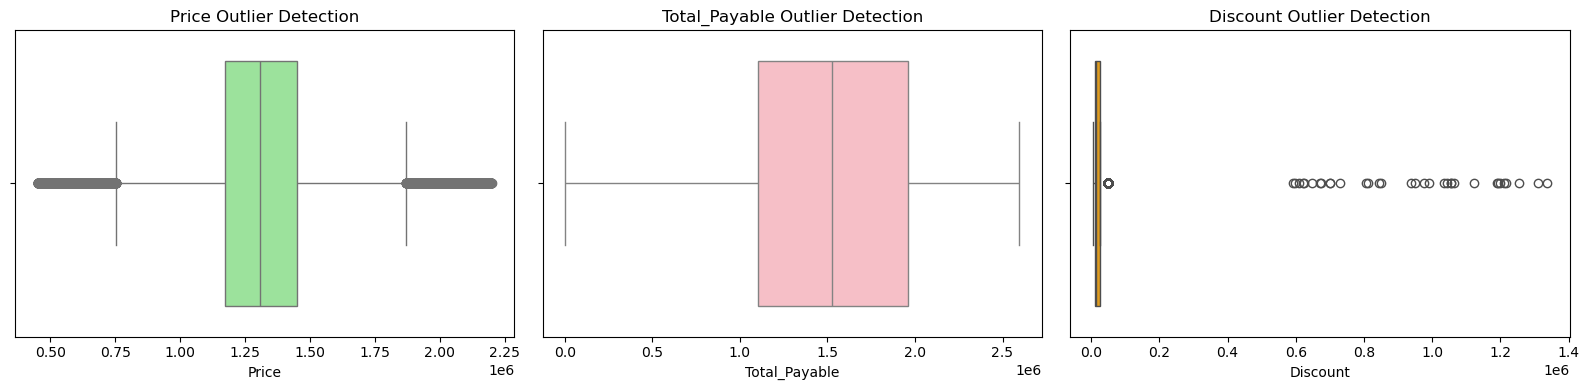

In [27]:
fig, ax = plt.subplots(1,3, figsize = (16,4))
sns.boxplot(x= df['Price'], ax= ax[0], color='lightgreen')
ax[0].set_title('Price Outlier Detection')

sns.boxplot(x= df['Total_Payable'], ax= ax[1], color= 'lightpink')
ax[1].set_title('Total_Payable Outlier Detection')

sns.boxplot(x= df['Discount'], ax= ax[2], color= 'orange')
ax[2].set_title('Discount Outlier Detection')

plt.tight_layout()
plt.show()

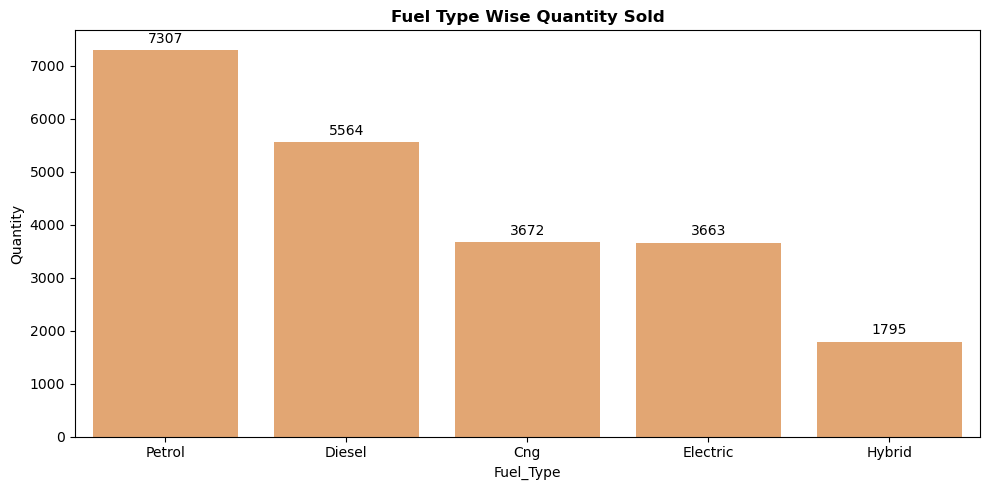

In [28]:
Fuel_Type_Wise_Quantity_Sold = df.groupby(['Fuel_Type'], as_index=False)['Quantity'].count().sort_values(by = 'Quantity', ascending=False)

plt.figure(figsize=(10,5))
ax = sns.barplot(x= 'Fuel_Type', y='Quantity', data= Fuel_Type_Wise_Quantity_Sold, color= 'sandybrown')
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.title('Fuel Type Wise Quantity Sold', fontweight='bold')
plt.tight_layout()
plt.show()

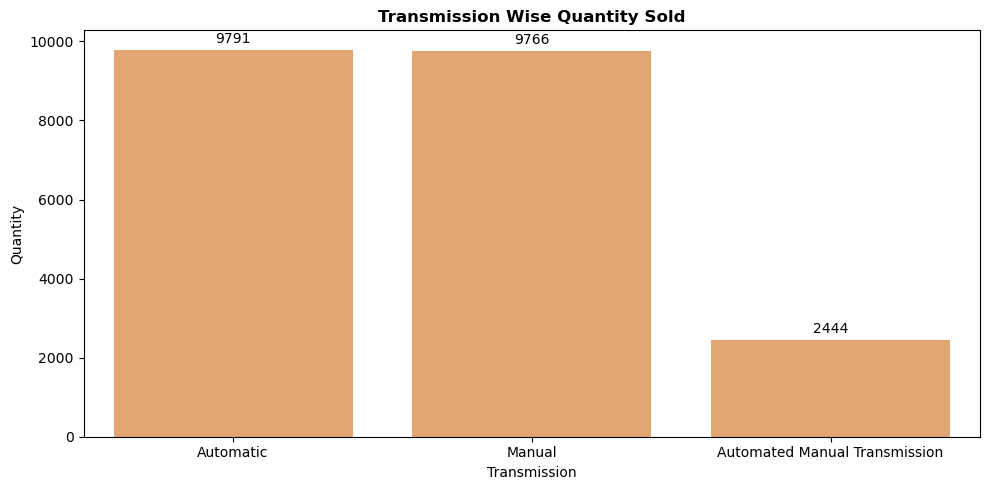

In [29]:
Transmission_Wise_Quantity_Sold = df.groupby(['Transmission'], as_index=False)['Quantity'].count().sort_values(by = 'Quantity', ascending=False)

plt.figure(figsize=(10,5))
ax = sns.barplot(x= 'Transmission', y='Quantity', data= Transmission_Wise_Quantity_Sold, color= 'sandybrown')
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.title('Transmission Wise Quantity Sold', fontweight='bold')
plt.tight_layout()
plt.show()

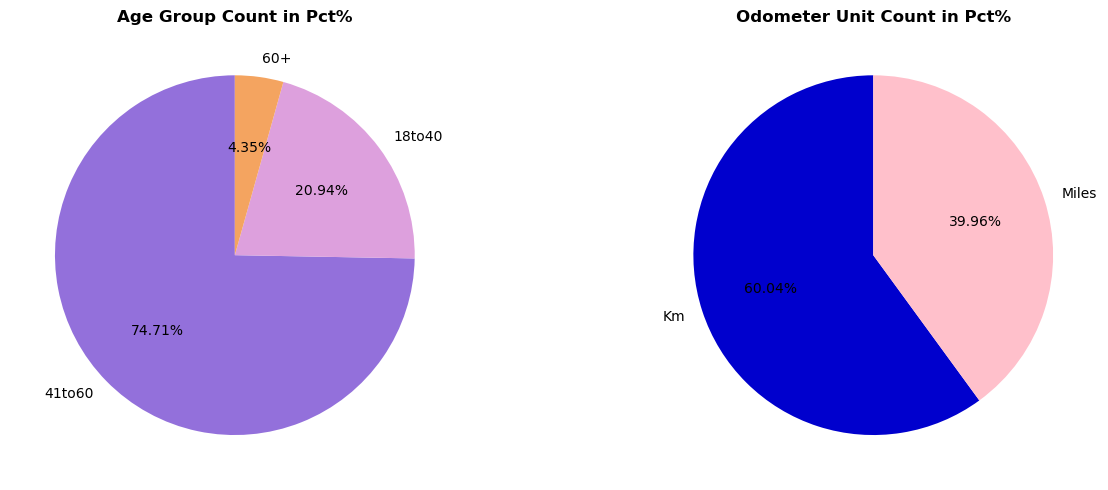

In [30]:
fig, axes= plt.subplots(1,2, figsize= (14,5))

Age_Group_Count = df['Age_Group'].value_counts()

axes[0].pie(
    Age_Group_Count.values,
    labels = Age_Group_Count.index,
    autopct= '%1.2f%%',
    startangle = 90,
    colors= ['mediumpurple', 'plum', 'sandybrown']
)
axes[0].set_title('Age Group Count in Pct%', fontweight='bold')

Odometer_Unit_Count = df['Odometer_Unit'].value_counts()

axes[1].pie(
    Odometer_Unit_Count.values,
    labels = Odometer_Unit_Count.index,
    autopct= '%1.2f%%',
    startangle = 90,
    colors= ['mediumblue', 'pink']
)
axes[1].set_title('Odometer Unit Count in Pct%', fontweight='bold')


plt.tight_layout()
plt.show()

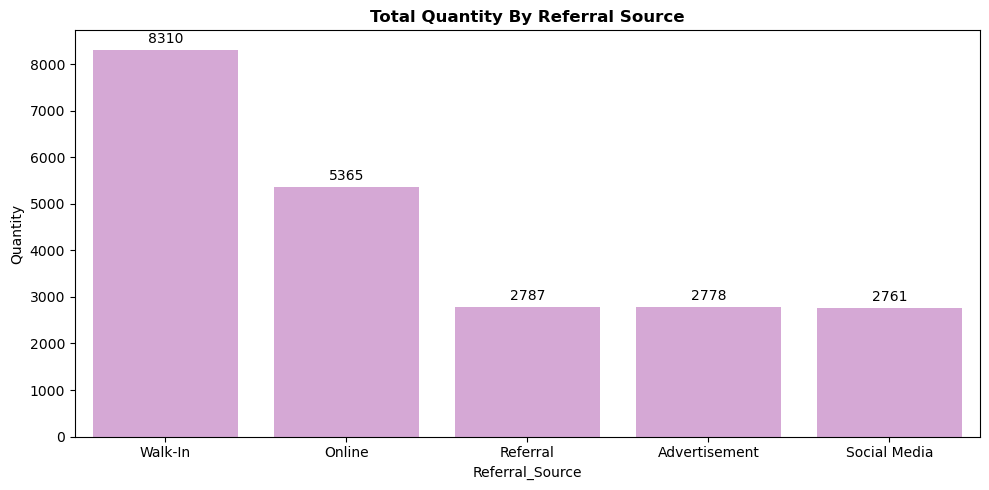

In [31]:
Total_Quantity_By_Referral_Source = df.groupby(['Referral_Source'], as_index=False)['Quantity'].count().sort_values(by= 'Quantity', ascending=False)

plt.figure(figsize=(10,5))
ax = sns.barplot(x= 'Referral_Source', y= 'Quantity', data= Total_Quantity_By_Referral_Source, color='plum')
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding= 3)

plt.title('Total Quantity By Referral Source', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

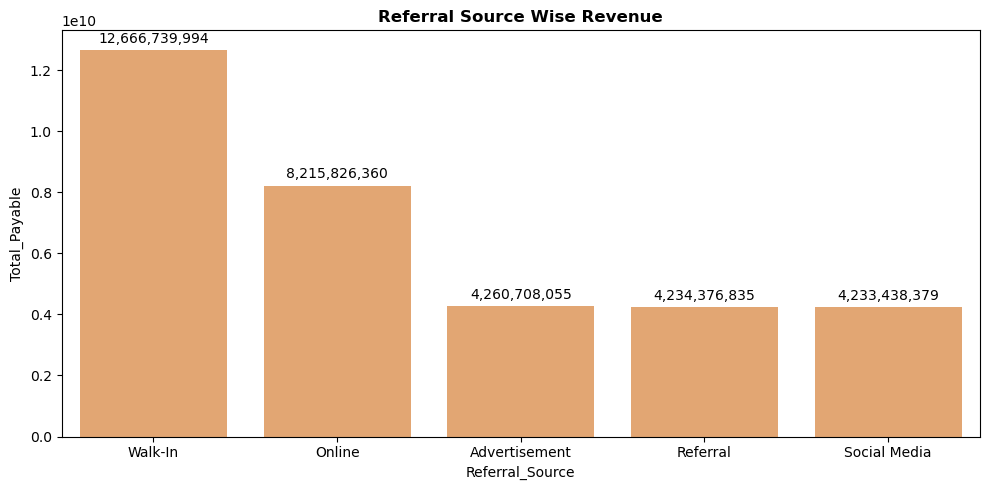

In [36]:
Referral_Source_Wise_Revenue = df.groupby(['Referral_Source'], 
            as_index=False)['Total_Payable'].sum().sort_values(by = 'Total_Payable', ascending=False)

plt.figure(figsize=(10,5))
ax = sns.barplot(x= 'Referral_Source', y='Total_Payable', data= Referral_Source_Wise_Revenue, color= 'sandybrown')
for container in ax.containers:
    ax.bar_label(container, labels=[f'{v:,.0f}' for v in container.datavalues], padding=3)
plt.title('Referral Source Wise Revenue', fontweight='bold')
plt.tight_layout()
plt.show()

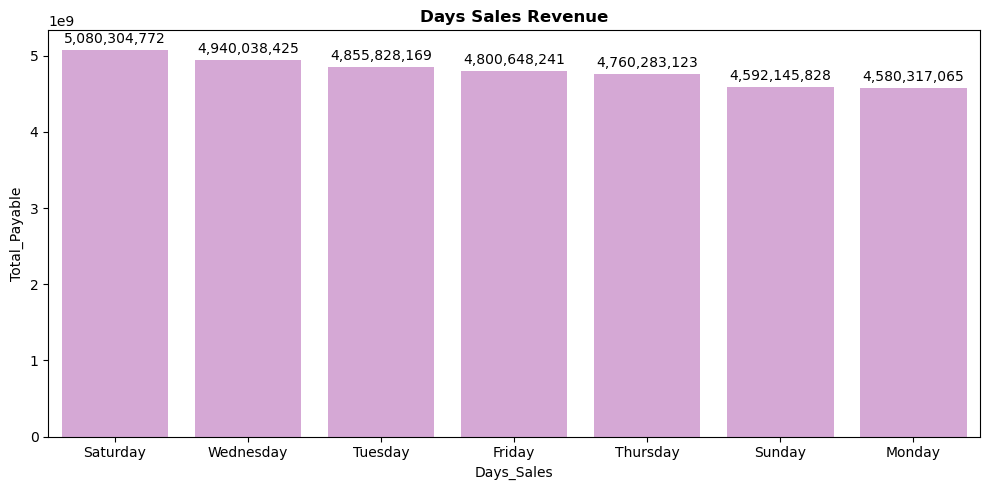

In [40]:
Days_Sales_Revenue = df.groupby(['Days_Sales'], as_index=False)['Total_Payable'].sum().sort_values(by= 'Total_Payable', ascending=False)

plt.figure(figsize=(10,5))
ax = sns.barplot(x= 'Days_Sales', y= 'Total_Payable', data= Days_Sales_Revenue, color='plum')
for container in ax.containers:
    ax.bar_label(container, labels=[f'{v:,.0f}' for v in container.datavalues], padding= 3)

plt.title('Days Sales Revenue', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

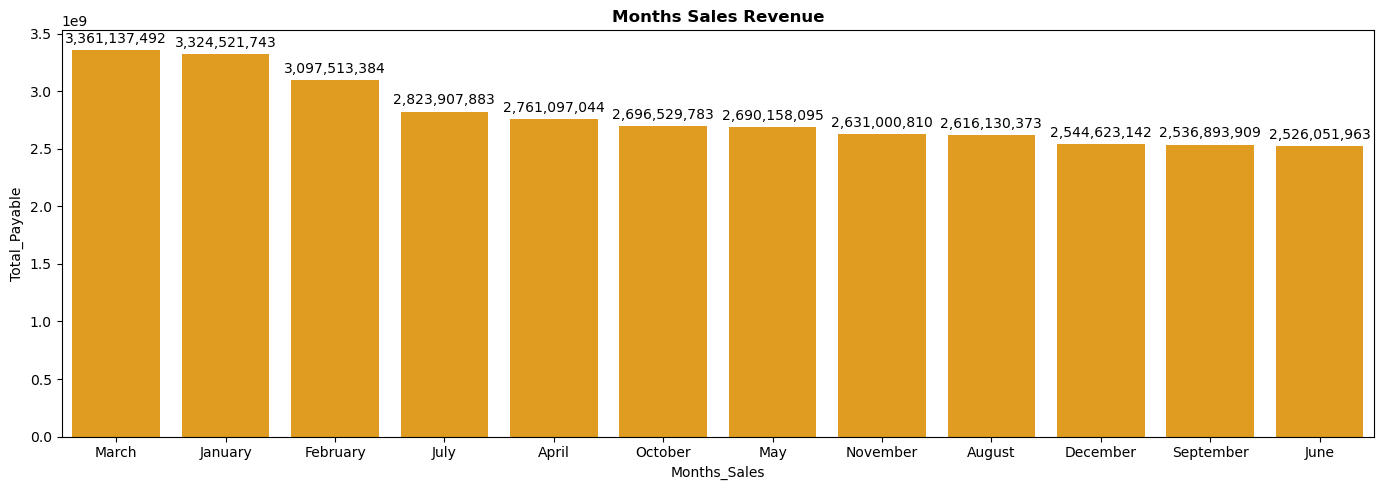

In [42]:
Months_Sales_Revenue = df.groupby(['Months_Sales'], as_index=False)['Total_Payable'].sum().sort_values(by= 'Total_Payable', ascending=False)

plt.figure(figsize=(14,5))
ax = sns.barplot(x= 'Months_Sales', y= 'Total_Payable', data= Months_Sales_Revenue, color='orange')
for container in ax.containers:
    ax.bar_label(container, labels=[f'{v:,.0f}' for v in container.datavalues], padding= 3)

plt.title('Months Sales Revenue', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

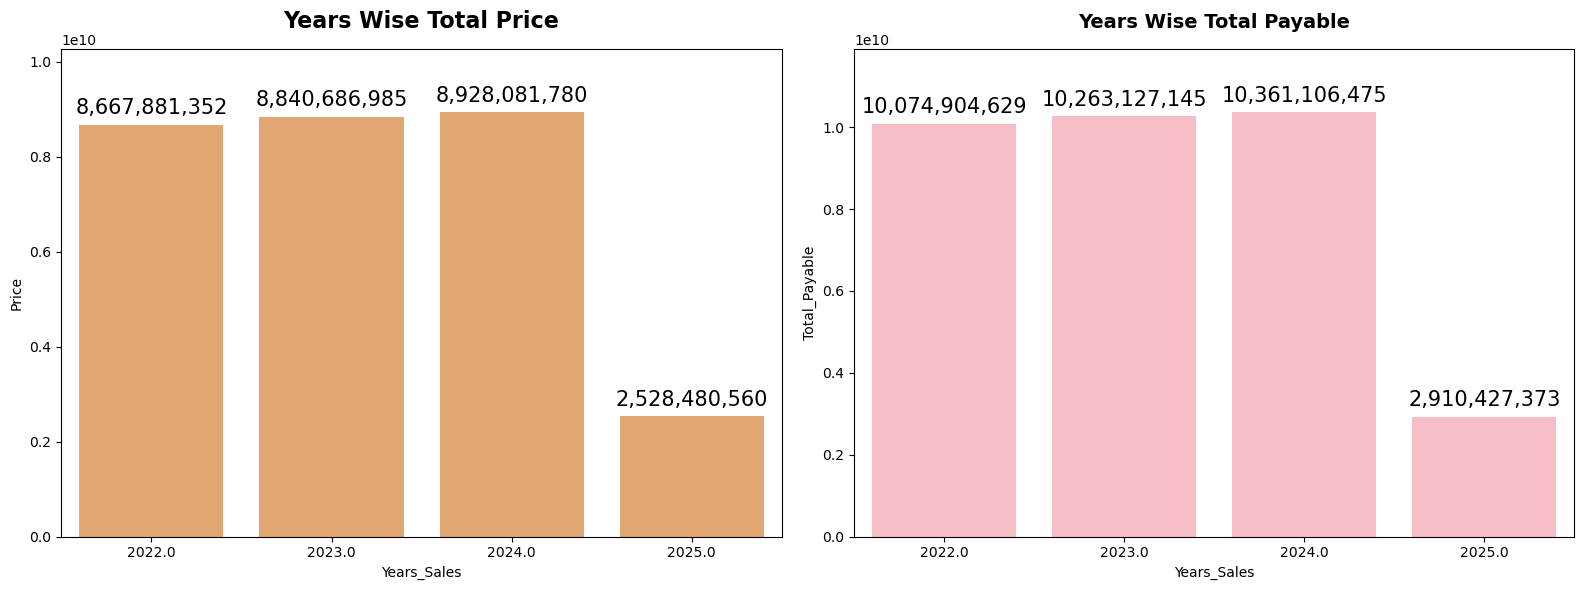

In [43]:
fig, axes = plt.subplots(1,2, figsize = (16,6))

Price_By_Year = df.groupby(['Years_Sales'], as_index=False)['Price'].sum().sort_values(by= 'Price', ascending= False)
sns.barplot(x= 'Years_Sales', y= 'Price', data= Price_By_Year,  color= 'sandybrown', ax= axes[0])

axes[0].set_ylim(0, Price_By_Year['Price'].max() * 1.15)
axes[0].set_title('Years Wise Total Price', fontsize=16, pad=15,  fontweight='bold')

for container in axes[0].containers:
    axes[0].bar_label(container, labels=[f'{v:,.0f}' for v in container.datavalues], padding= 5, fontsize=15)

Total_Payable_By_Year = df.groupby(['Years_Sales'], as_index=False)['Total_Payable'].sum().sort_values(by= 'Total_Payable', ascending=False)
sns.barplot(x='Years_Sales', y= 'Total_Payable', data= Total_Payable_By_Year,  color= 'lightpink', ax= axes[1])

axes[1].set_ylim(0, Total_Payable_By_Year['Total_Payable'].max() * 1.15)
axes[1].set_title('Years Wise Total Payable', fontsize=14, pad=15,  fontweight='bold')

for container in axes[1].containers:
    axes[1].bar_label(container, labels=[f'{v:,.0f}' for v in container.datavalues], padding=5, fontsize=15)


plt.tight_layout()
plt.show()

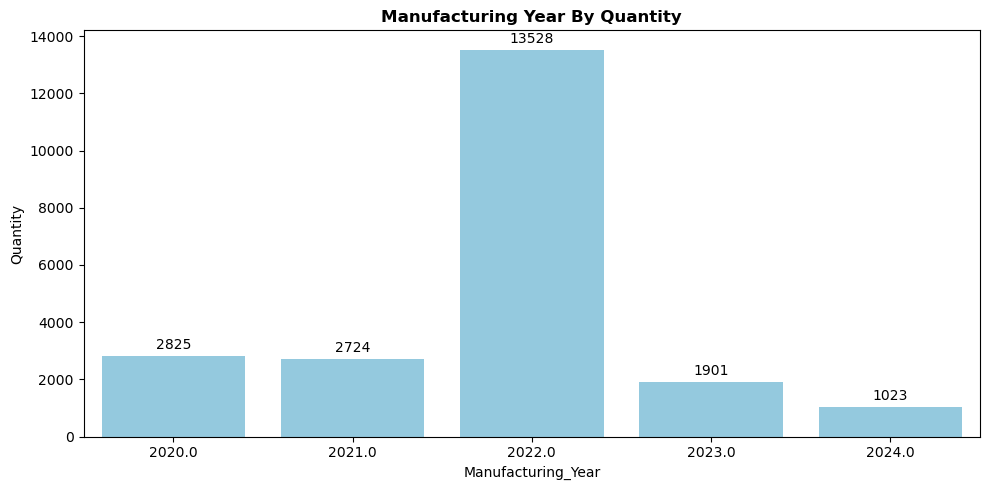

In [44]:
Manufacturing_Year_By_Quantity = df.groupby(['Manufacturing_Year'], as_index=False)['Quantity'].count().sort_values(by= 'Quantity', ascending=False)

plt.figure(figsize=(10,5))
ax = sns.barplot(x= 'Manufacturing_Year', y= 'Quantity', data= Manufacturing_Year_By_Quantity, color='skyblue')
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding= 3)

plt.title('Manufacturing Year By Quantity', fontsize=12,  fontweight='bold')
plt.tight_layout()
plt.show()

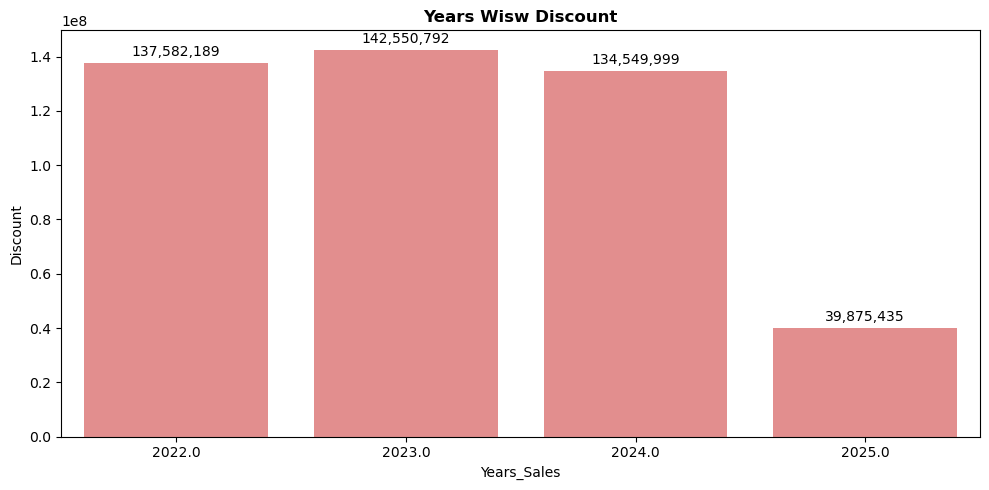

In [52]:
Years_Wisw_Discount = df.groupby(['Years_Sales'], as_index=False)['Discount'].sum().sort_values(by= 'Discount', ascending=False)

plt.figure(figsize=(10,5))
ax = sns.barplot(x= 'Years_Sales', y= 'Discount', data= Years_Wisw_Discount, color='lightcoral')
for container in ax.containers:
    ax.bar_label(container, labels=[f'{v:,.0f}' for v in container.datavalues], padding= 3)

plt.title('Years Wisw Discount', fontsize=12,  fontweight='bold')
plt.tight_layout()
plt.show()

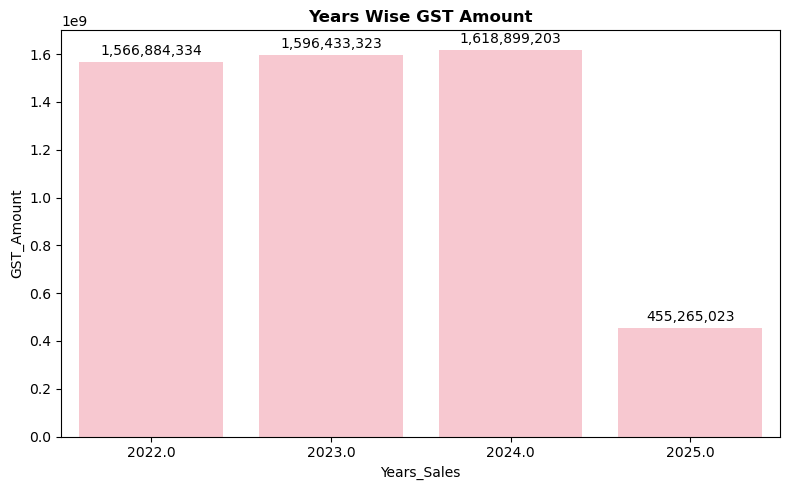

In [53]:
Years_Wise_GST_Amount = df.groupby(['Years_Sales'], as_index=False)['GST_Amount'].sum().sort_values(by= 'GST_Amount', ascending=False)

plt.figure(figsize=(8,5))
ax = sns.barplot(x= 'Years_Sales', y= 'GST_Amount', data= Years_Wise_GST_Amount, color='pink')
for container in ax.containers:
    ax.bar_label(container, labels=[f'{v:,.0f}' for v in container.datavalues], padding= 3)

plt.title('Years Wise GST Amount', fontsize=12,  fontweight='bold')    
plt.tight_layout()
plt.show()

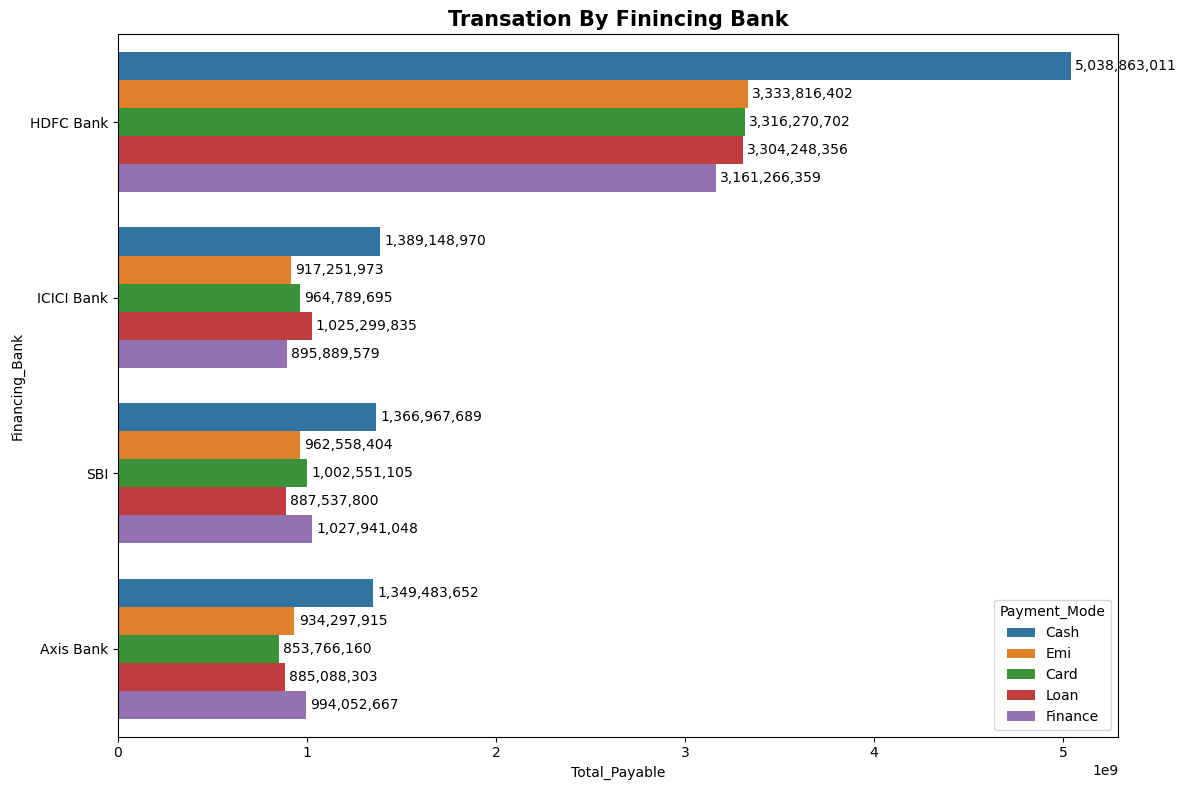

In [58]:
Transation_By_Finincing_Bank = df.groupby(['Financing_Bank','Payment_Mode'], as_index=False)['Total_Payable'].sum().sort_values(by= 'Total_Payable', ascending=False)

plt.figure(figsize=(12,8))
ax = sns.barplot(x= 'Total_Payable', y= 'Financing_Bank', hue= 'Payment_Mode', data= Transation_By_Finincing_Bank)
for container in ax.containers:
    ax.bar_label(container, labels=[f'{v:,.0f}' for v in container.datavalues], padding= 3)

plt.title('Transation By Finincing Bank', fontsize=15, fontweight = 'bold')
plt.tight_layout()
plt.show()

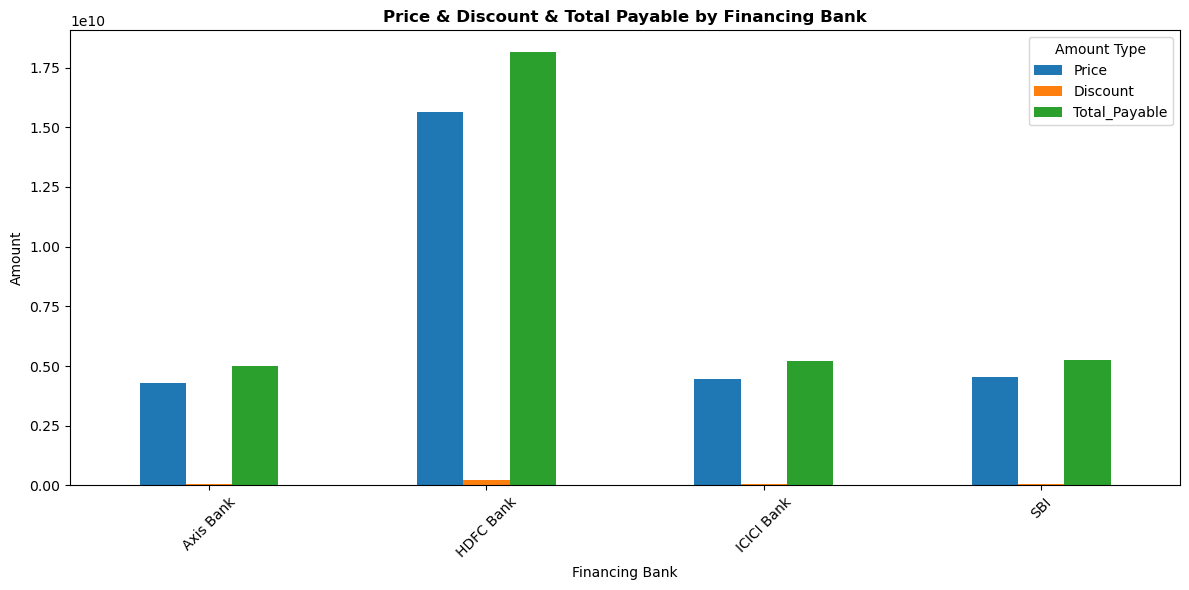

In [59]:
bank_data = df.groupby('Financing_Bank')[['Price', 'Discount', 'Total_Payable']].sum()

bank_data.plot(kind='bar', figsize=(12,6))

plt.title('Price & Discount & Total Payable by Financing Bank', fontweight = 'bold')
plt.xlabel('Financing Bank')
plt.ylabel('Amount')
plt.xticks(rotation=45)
plt.legend(title='Amount Type')
plt.tight_layout()
plt.show()

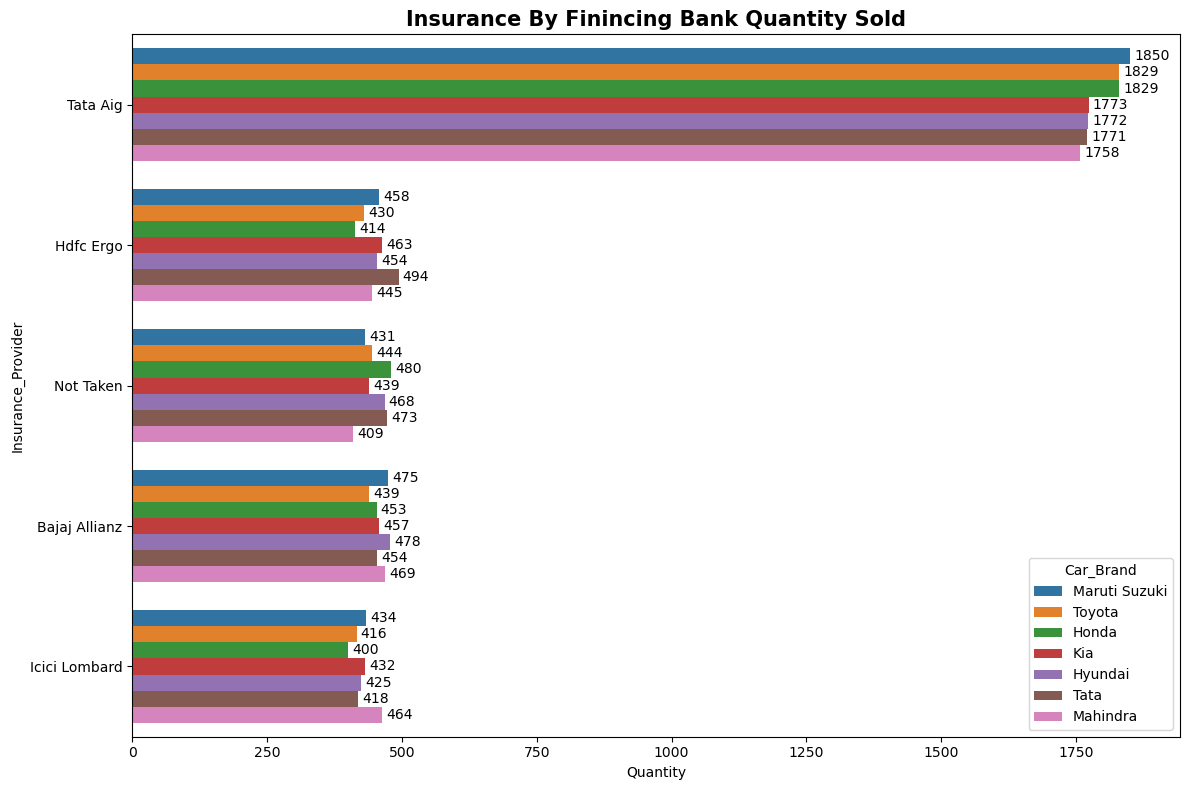

In [60]:
Insurance_By_Finincing_Bank_Quantity_Sold = df.groupby(['Insurance_Provider','Car_Brand'], 
        as_index=False)['Quantity'].sum().sort_values(by= 'Quantity', ascending=False)

plt.figure(figsize=(12,8))
ax = sns.barplot(x= 'Quantity', y= 'Insurance_Provider', hue= 'Car_Brand', data= Insurance_By_Finincing_Bank_Quantity_Sold)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding= 3)

plt.title('Insurance By Finincing Bank Quantity Sold', fontsize=15, fontweight = 'bold')
plt.tight_layout()
plt.show()

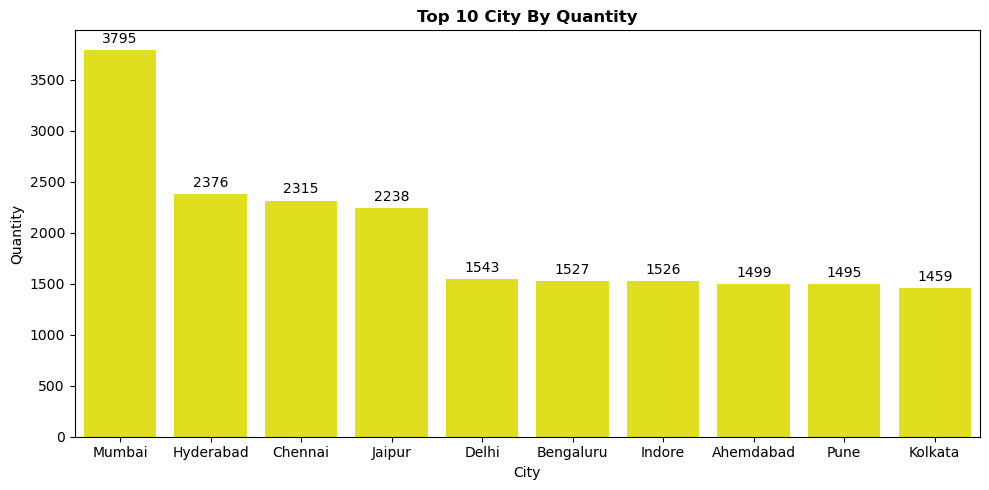

In [61]:
Top_10_City_By_Quantity = df.groupby(['City'], as_index=False)['Quantity'].sum().sort_values(by= 'Quantity', ascending=False).head(10)

plt.figure(figsize=(10,5))
ax = sns.barplot(x= 'City', y= 'Quantity', data= Top_10_City_By_Quantity, color='yellow')
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding= 3)

plt.title('Top 10 City By Quantity', fontsize=12, fontweight = 'bold')
plt.tight_layout()
plt.show()

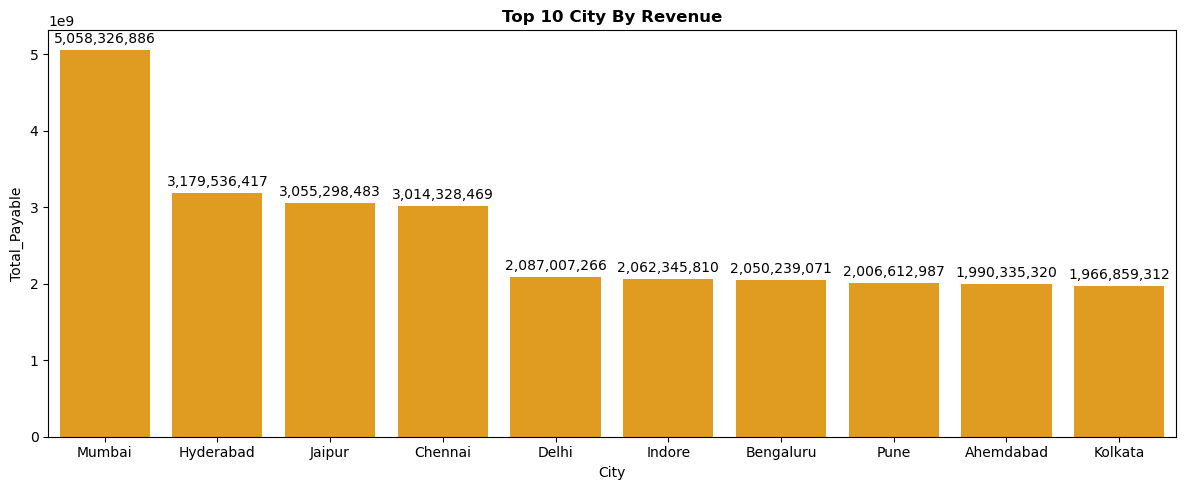

In [63]:
Top_10_City_By_Revenue = df.groupby(['City'], as_index=False)['Total_Payable'].sum().sort_values(by= 'Total_Payable', ascending=False).head(10)

plt.figure(figsize=(12,5))
ax = sns.barplot(x= 'City', y= 'Total_Payable', data= Top_10_City_By_Revenue, color='orange')
for container in ax.containers:
    ax.bar_label(container, labels=[f'{v:,.0f}' for v in container.datavalues], padding= 3)

plt.title('Top 10 City By Revenue', fontsize=12, fontweight = 'bold')
plt.tight_layout()
plt.show()

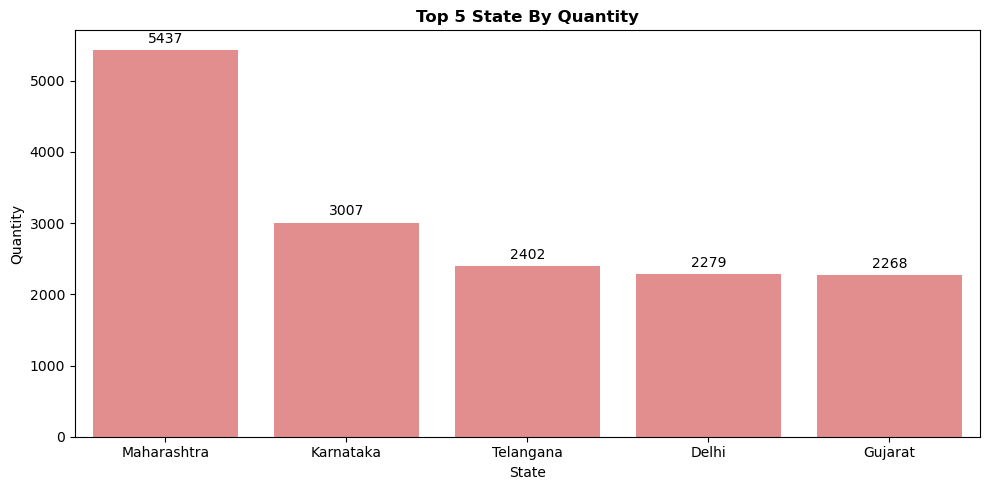

In [64]:
Top_5_State_By_Quantity = df.groupby(['State'], as_index=False)['Quantity'].sum().sort_values(by= 'Quantity', ascending=False).head(5)

plt.figure(figsize=(10,5))
ax = sns.barplot(x= 'State', y= 'Quantity', data= Top_5_State_By_Quantity, color='lightcoral')
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding= 3)

plt.title('Top 5 State By Quantity', fontsize=12, fontweight = 'bold')
plt.tight_layout()
plt.show()

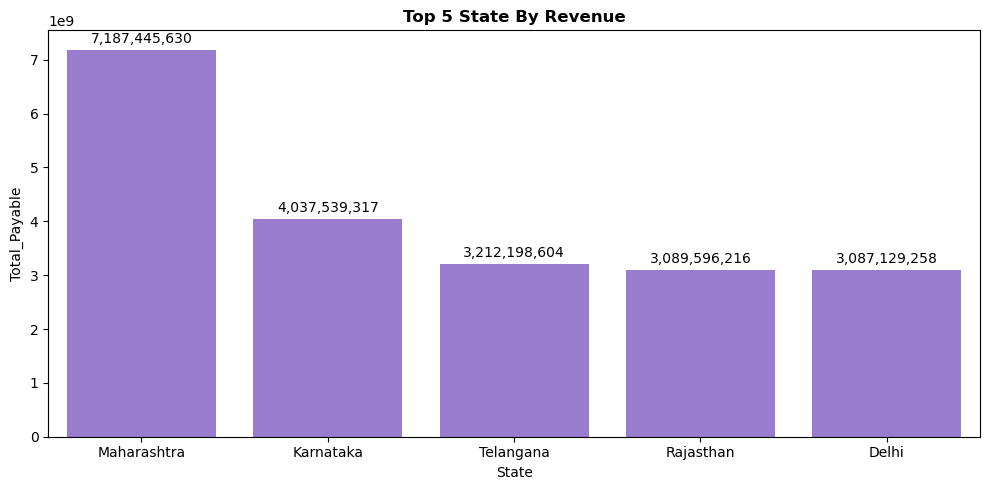

In [65]:
Top_5_State_By_Revenue = df.groupby(['State'], as_index=False)['Total_Payable'].sum().sort_values(by= 'Total_Payable', ascending=False).head(5)

plt.figure(figsize=(10,5))
ax = sns.barplot(x= 'State', y= 'Total_Payable', data= Top_5_State_By_Revenue, color='mediumpurple')
for container in ax.containers:
    ax.bar_label(container, labels=[f'{v:,.0f}' for v in container.datavalues], padding= 3)

plt.title('Top 5 State By Revenue', fontsize=12, fontweight = 'bold')
plt.tight_layout()
plt.show()

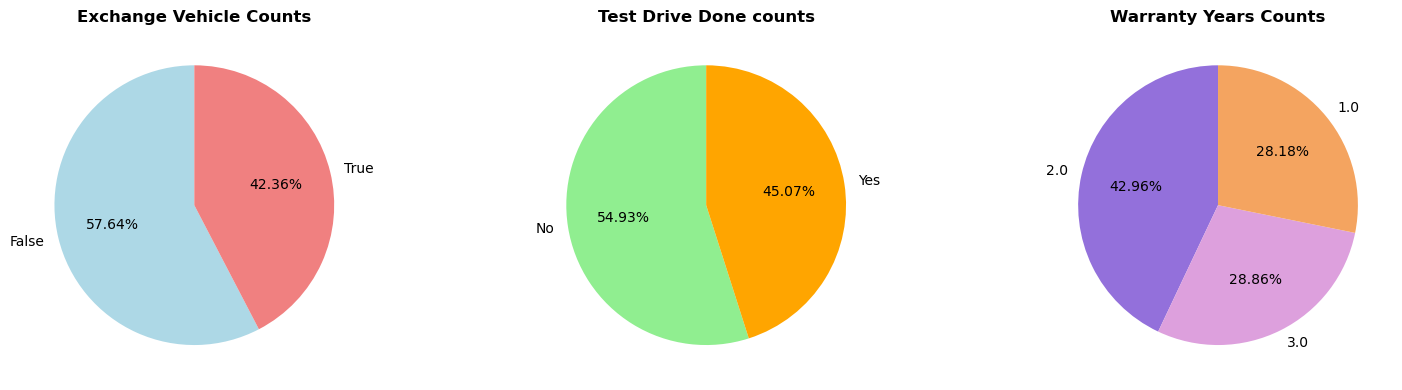

In [66]:
fig, axes = plt.subplots(1,3, figsize= (16,4))

Exchange_Vehicle_Count = df['Exchange_Vehicle'].value_counts()

axes[0].pie(
    Exchange_Vehicle_Count.values,
    labels= Exchange_Vehicle_Count.index,
    autopct = '%1.2f%%',
    startangle = 90,
    colors= ['lightblue', 'lightcoral']
)
axes[0].set_title('Exchange Vehicle Counts', fontweight = 'bold')

Test_Drive_Done_count = df['Test_Drive_Done'].value_counts()

axes[1].pie(
    Test_Drive_Done_count.values,
    labels= Test_Drive_Done_count.index,
    autopct = '%1.2f%%',
    startangle= 90,
    colors= ['lightgreen', 'orange']
)
axes[1].set_title('Test Drive Done counts', fontweight = 'bold')

Warranty_Years_Count = df['Warranty_Years'].value_counts()

axes[2].pie(
    Warranty_Years_Count.values,
    labels= Warranty_Years_Count.index,
    autopct= '%1.2f%%',
    startangle= 90,
    colors= ['mediumpurple', 'plum', 'sandybrown']
)
axes[2].set_title('Warranty Years Counts', fontweight = 'bold')

plt.tight_layout()
plt.show()

In [203]:
df.columns

Index(['Sale_ID', 'Sale_Date', 'Delivery_Date', 'Registration_Number',
       'Customer_Name', 'Customer_Age', 'Customer_Phone', 'Customer_Email',
       'Car_Brand', 'Car_Model', 'Fuel_Type', 'Transmission', 'Color',
       'Manufacturing_Year', 'KM_Driven', 'Odometer_Unit', 'Price',
       'GST_Amount', 'Discount', 'Total_Payable', 'Payment_Mode',
       'Financing_Bank', 'Insurance_Provider', 'Salesperson', 'City', 'State',
       'Warranty_Years', 'Test_Drive_Done', 'Exchange_Vehicle',
       'Referral_Source', 'Quantity', 'Years_Sales', 'Months_Sales',
       'Days_Sales', 'Age_Group'],
      dtype='object')

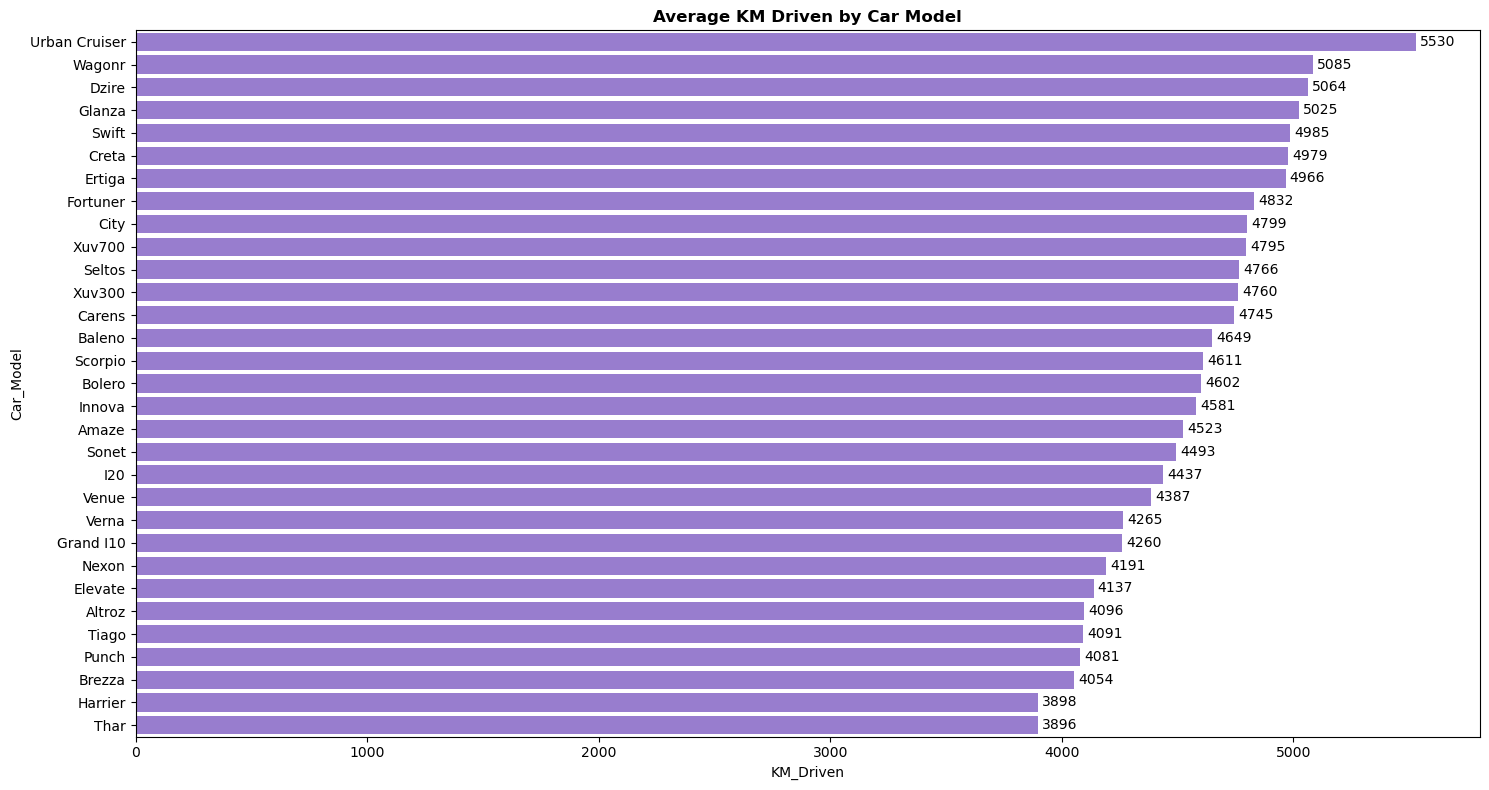

In [67]:
Average_KM_Driven_by_Car_Model = df.groupby(['Car_Model'], as_index=False)['KM_Driven'].mean().sort_values(by= 'KM_Driven', ascending=False)

plt.figure(figsize=(15,8))
ax = sns.barplot(x= 'KM_Driven', y= 'Car_Model', data= Average_KM_Driven_by_Car_Model, color='mediumpurple')
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding= 3)

plt.title('Average KM Driven by Car Model', fontsize=12, fontweight = 'bold')
plt.tight_layout()
plt.show()